<a href="https://colab.research.google.com/github/Ahmettufan3310/74-musteri-segmentasyonu-rfm/blob/main/notebooks/05_pca_gorsellestirme.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

base = "https://raw.githubusercontent.com/Ahmettufan3310/74-musteri-segmentasyonu-rfm/main/data"
olcekli = pd.read_csv(f"{base}/rfm_olcekli.csv")
sonuc = pd.read_csv(f"{base}/kume_sonuclari.csv")

# ölçekli R,F,M + küme etiketi
df = olcekli.merge(sonuc[['CustomerID', 'Kume']], on='CustomerID')
X = df[['Recency', 'Frequency', 'Monetary']]
print(df.shape)
print(df['Kume'].value_counts().sort_index())

(4333, 6)
Kume
0     837
1     714
2    1187
3    1595
Name: count, dtype: int64


In [2]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
bilesenler = pca.fit_transform(X)
df['PC1'] = bilesenler[:, 0]
df['PC2'] = bilesenler[:, 1]

print("Açıklanan varyans:", pca.explained_variance_ratio_.round(3))
print("Toplam açıklanan varyans:", round(pca.explained_variance_ratio_.sum(), 3))

Açıklanan varyans: [0.753 0.187]
Toplam açıklanan varyans: 0.94


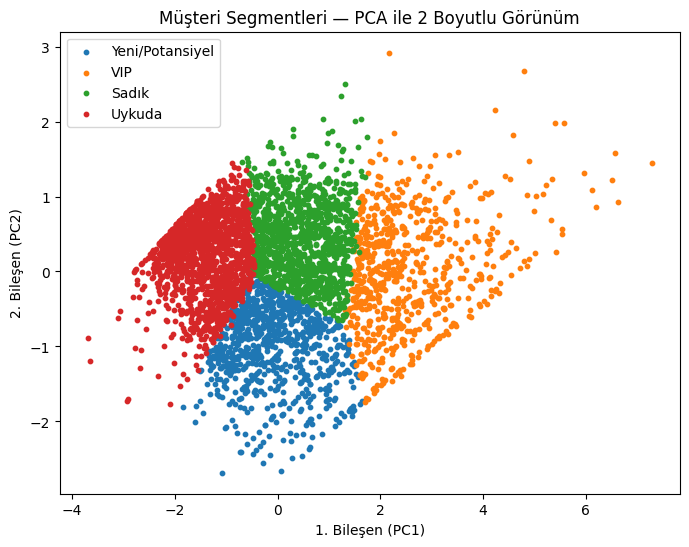

In [3]:
import matplotlib.pyplot as plt

isim = {0: 'Yeni/Potansiyel', 1: 'VIP', 2: 'Sadık', 3: 'Uykuda'}

plt.figure(figsize=(8, 6))
for k in sorted(df['Kume'].unique()):
    alt = df[df['Kume'] == k]
    plt.scatter(alt['PC1'], alt['PC2'], s=10, label=isim[k])
plt.xlabel('1. Bileşen (PC1)')
plt.ylabel('2. Bileşen (PC2)')
plt.title('Müşteri Segmentleri — PCA ile 2 Boyutlu Görünüm')
plt.legend()
plt.show()